In [87]:
#Question 1 a
import pandas as pd

df = pd.read_csv("/Users/julianafuller/Downloads/train.csv")


df.head()




,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [88]:
#Question 1 b
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [89]:
#Question 1 c
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns.tolist()

categorical_cols = df.select_dtypes(include=[ 'str', 'bool']).columns.tolist()

print("Numerical Variables:", numerical_cols)
print("Categorical Variables:", categorical_cols)

Numerical Variables: ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']
Categorical Variables: ['Name', 'Sex', 'Ticket', 'Cabin', 'Embarked']


In [90]:
#Question 1 d
missing_count = df.isnull().sum()
print(missing_count)
missing_percentage = (df.isnull().sum() / len(df)) * 100
print(missing_percentage.round(2))



PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
PassengerId     0.00
Survived        0.00
Pclass          0.00
Name            0.00
Sex             0.00
Age            19.87
SibSp           0.00
Parch           0.00
Ticket          0.00
Fare            0.00
Cabin          77.10
Embarked        0.22
dtype: float64


In [91]:
#Question 1 e
duplicate_count = df.duplicated().sum()
print("Total Duplicate Rows:", duplicate_count)

Total Duplicate Rows: 0


In [92]:
#Question 1 f
cols = ['Age', 'Fare']

for col in cols:
  
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    

    IQR = Q3 - Q1
    

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
  
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    
    # Print the results
    print(f"{col}")
    print(f"Lower Bound: {lower_bound} | Upper Bound: {upper_bound}")
    print(f"Number of Outliers: {len(outliers)}\n")
    display(outliers)
    print("\n")


Age
Lower Bound: -6.6875 | Upper Bound: 64.8125
Number of Outliers: 11



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
33,34,0,2,"Wheadon, Mr. Edward H",male,66.0,0,0,C.A. 24579,10.5000,NaN,S
54,55,0,1,"Ostby, Mr. Engelhart Cornelius",male,65.0,0,1,113509,61.9792,B30,C
96,97,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,A5,C
116,117,0,3,"Connors, Mr. Patrick",male,70.5,0,0,370369,7.7500,NaN,Q
280,281,0,3,"Duane, Mr. Frank",male,65.0,0,0,336439,7.7500,NaN,Q
456,457,0,1,"Millet, Mr. Francis Davis",male,65.0,0,0,13509,26.5500,E38,S
493,494,0,1,"Artagaveytia, Mr. Ramon",male,71.0,0,0,PC 17609,49.5042,NaN,C
630,631,1,1,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,0,0,27042,30.0000,A23,S
672,673,0,2,"Mitchell, Mr. Henry Michael",male,70.0,0,0,C.A. 24580,10.5000,NaN,S
745,746,0,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,WE/P 5735,71.0000,B22,S




Fare
Lower Bound: -26.724 | Upper Bound: 65.6344
Number of Outliers: 116



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.0000,C23 C25 C27,S
31,32,1,1,"Spencer, Mrs. William Augustus (Marie Eugenie)",female,NaN,1,0,PC 17569,146.5208,B78,C
34,35,0,1,"Meyer, Mr. Edgar Joseph",male,28.0,1,0,PC 17604,82.1708,NaN,C
52,53,1,1,"Harper, Mrs. Henry Sleeper (Myna Haxtun)",female,49.0,1,0,PC 17572,76.7292,D33,C
...,...,...,...,...,...,...,...,...,...,...,...,...
846,847,0,3,"Sage, Mr. Douglas Bullen",male,NaN,8,2,CA. 2343,69.5500,NaN,S
849,850,1,1,"Goldenberg, Mrs. Samuel L (Edwiga Grabowska)",female,NaN,1,0,17453,89.1042,C92,C
856,857,1,1,"Wick, Mrs. George Dennick (Mary Hitchcock)",female,45.0,1,1,36928,164.8667,NaN,S
863,864,0,3,"Sage, Miss. Dorothy Edith ""Dolly""",female,NaN,8,2,CA. 2343,69.5500,NaN,S


Write down your findings:

This dataset contains passenger information from the Titanic, including details such as sex, age, survival status, and passenger class. While there are no duplicate records, a few columns columns contain a significant number of missing values notably Age and Cabin. These gaps will be addressed during the data cleaning phase to ensure the dataset is accurate and reliable for analysis.

In [93]:
# Question 2 a
df_copy = df.copy()
df_copy.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [94]:
# Question 2 b 

#we are checking if we removed all rows that had no info in at least one of the columns
rows_to_drop = df_copy.isna().any(axis=1).sum()
pct_lost = (rows_to_drop / len(df_copy)) * 100
print(f"Rows to remove: {rows_to_drop} out of {len(df_copy)}")
print(f"Percentage of dataset lost: {pct_lost:.2f}%")


#too much, since cabin is probably not needed, if we discounted it, what it would be now.
rows_to_drop_2 = df_copy.drop(columns=['Cabin']).isna().any(axis=1).sum()
print(f"Rows to be removed (ignoring Cabin): {rows_to_drop_2}")
pct_lost_2 = (rows_to_drop_2 / len(df_copy)) * 100
print(f"Rows to remove: {rows_to_drop_2} out of {len(df_copy)}")
print(f"Percentage of dataset lost: {pct_lost_2:.2f}%")

#Much better. I wouldn't use the retain strategy because I do not want filler data, especially in numerical columns, as running calculations and statistics on "Unknown" values would make the data difficult to work with.
#I also don't want to impute the Age column because I want to avoid making false assumptions about a passenger's age, making removing the missing rows the best option.

df_clean = df_copy.dropna(subset=df_copy.columns.drop(['Cabin']))

print(len(df_clean))
display(df_clean)


Rows to remove: 708 out of 891
Percentage of dataset lost: 79.46%
Rows to be removed (ignoring Cabin): 179
Rows to remove: 179 out of 891
Percentage of dataset lost: 20.09%
712


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
885,886,0,3,"Rice, Mrs. William (Margaret Norton)",female,39.0,0,5,382652,29.1250,NaN,Q
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [ ]:
# Question 2 c
cols = ['Age', 'Fare', 'Survived', 'Pclass', 'SibSp']

for col in cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[(df_clean[col] < lower_bound) | (df_clean[col] > upper_bound)]

    print(f"=== {col} (Total Outliers: {len(outliers)}) ===")

    print(f"Top 5 Highest {col} Outliers:")
    display(outliers.sort_values(by=col, ascending=False).head(5))

    print(f"Top 5 Lowest {col} Outliers:")
    display(outliers.sort_values(by=col, ascending=True).head(5))
    print("\n")


#I would keep all outliers because they represent real passenger data rather than errors. All ages fall within a realistic human lifespan, and the higher fares align with expected prices for luxury upper-class tickets. 

=== Age (Total Outliers: 8) ===
Top 5 Highest Age Outliers:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
630,631,1,1,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,0,0,27042,30.0000,A23,S
851,852,0,3,"Svensson, Mr. Johan",male,74.0,0,0,347060,7.7750,NaN,S
96,97,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,A5,C
493,494,0,1,"Artagaveytia, Mr. Ramon",male,71.0,0,0,PC 17609,49.5042,NaN,C
116,117,0,3,"Connors, Mr. Patrick",male,70.5,0,0,370369,7.7500,NaN,Q


Top 5 Lowest Age Outliers:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
33,34,0,2,"Wheadon, Mr. Edward H",male,66.0,0,0,C.A. 24579,10.5000,NaN,S
672,673,0,2,"Mitchell, Mr. Henry Michael",male,70.0,0,0,C.A. 24580,10.5000,NaN,S
745,746,0,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,WE/P 5735,71.0000,B22,S
116,117,0,3,"Connors, Mr. Patrick",male,70.5,0,0,370369,7.7500,NaN,Q
96,97,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,A5,C




=== Fare (Total Outliers: 95) ===
Top 5 Highest Fare Outliers:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
679,680,1,1,"Cardeza, Mr. Thomas Drake Martinez",male,36.0,0,1,PC 17755,512.3292,B51 B53 B55,C
737,738,1,1,"Lesurer, Mr. Gustave J",male,35.0,0,0,PC 17755,512.3292,B101,C
258,259,1,1,"Ward, Miss. Anna",female,35.0,0,0,PC 17755,512.3292,NaN,C
438,439,0,1,"Fortune, Mr. Mark",male,64.0,1,4,19950,263.0000,C23 C25 C27,S
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.0000,C23 C25 C27,S


... (10 outputs left out)



=== SibSp (Total Outliers: 35) ===
Top 5 Highest SibSp Outliers:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
59,60,0,3,"Goodwin, Master. William Frederick",male,11.0,5,2,CA 2144,46.9,NaN,S
683,684,0,3,"Goodwin, Mr. Charles Edward",male,14.0,5,2,CA 2144,46.9,NaN,S
71,72,0,3,"Goodwin, Miss. Lillian Amy",female,16.0,5,2,CA 2144,46.9,NaN,S
480,481,0,3,"Goodwin, Master. Harold Victor",male,9.0,5,2,CA 2144,46.9,NaN,S
386,387,0,3,"Goodwin, Master. Sidney Leonard",male,1.0,5,2,CA 2144,46.9,NaN,S


Top 5 Lowest SibSp Outliers:


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.075,NaN,S
819,820,0,3,"Skoog, Master. Karl Thorsten",male,10.0,3,2,347088,27.900,NaN,S
24,25,0,3,"Palsson, Miss. Torborg Danira",female,8.0,3,1,349909,21.075,NaN,S
27,28,0,1,"Fortune, Mr. Charles Alexander",male,19.0,3,2,19950,263.000,C23 C25 C27,S
374,375,0,3,"Palsson, Miss. Stina Viola",female,3.0,3,1,349909,21.075,NaN,S


In [ ]:
# Question 2 d
num_cols = ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

#make sure that the values in the string and numerical columns are their correct data type. This is to ensure that there isn't any values that could cause issues with future analysis.

for col in num_cols:
    original = df_clean[col].copy()


    converted = pd.to_numeric(df_clean[col], errors='coerce')
    bad_values = df_clean.loc[df_clean[col].notna() & converted.isna(), col]

    if len(bad_values) > 0:
        print(f"[{col}] Warning: Found {len(bad_values)} invalid string(s) converted to NaN: {bad_values.unique()}")

    df[col] = converted

  
    values_changed = len(bad_values) > 0
    dtype_changed = str(original.dtype) != str(df_clean[col].dtype)

    if not values_changed and not dtype_changed:
        print(f"[{col}] No changes needed (already {df_clean[col].dtype}).")
    else:
        print(f"[{col}] Updated -> Invalid strings coerced: {values_changed} | Dtype changed: {dtype_changed} ({original.dtype} -> {df_clean[col].dtype})")



        num_cols = ['PassengerId', 'Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

for col in num_cols:
    original = df_clean[col].copy()


    converted = pd.to_numeric(df_clean[col], errors='coerce')
    bad_values = df_clean.loc[df_clean[col].notna() & converted.isna(), col]

    if len(bad_values) > 0:
        print(f"[{col}] Warning: Found {len(bad_values)} invalid string(s) converted to NaN: {bad_values.unique()}")


    df_clean[col] = converted


    values_changed = len(bad_values) > 0
    dtype_changed = str(original.dtype) != str(df_clean[col].dtype)

    if not values_changed and not dtype_changed:
        print(f"[{col}] No changes needed (already {df_clean[col].dtype}).")
    else:
        print(f"[{col}] Updated -> Invalid strings coerced: {values_changed} | Dtype changed: {dtype_changed} ({original.dtype} -> {df_clean[col].dtype})")



[PassengerId] No changes needed (already int64).
[Survived] No changes needed (already int64).
[Pclass] No changes needed (already int64).
[Age] No changes needed (already float64).
[SibSp] No changes needed (already int64).
[Parch] No changes needed (already int64).
[Fare] No changes needed (already float64).
[PassengerId] No changes needed (already int64).
[Survived] No changes needed (already int64).
[Pclass] No changes needed (already int64).
[Age] No changes needed (already float64).
[SibSp] No changes needed (already int64).
[Parch] No changes needed (already int64).
[Fare] No changes needed (already float64).


In [ ]:

# Question 2 e

total_duplicates = df_clean.duplicated().sum()
print(f"Overall Duplicate Rows: {total_duplicates} (Has Duplicates: {total_duplicates > 0})\n")


summary = pd.DataFrame({
    'Data_Type': df_clean.dtypes,
    'Missing_Count': df_clean.isna().sum()
})

display(summary)
#no more missing data, not counting cabin column, which is fine because it is not vital towards any analysis. 

Overall Duplicate Rows: 0 (Has Duplicates: False)



,Data_Type,Missing_Count
PassengerId,int64,0
Survived,int64,0
Pclass,int64,0
Name,str,0
Sex,str,0
Age,float64,0
SibSp,int64,0
Parch,int64,0
Ticket,str,0
Fare,float64,0


Overall, we checked for duplicate records, verified that all values matched their expected column data types, and removed rows with missing values (excluding Cabin) to ensure a clean, reliable dataset for analysis.

In [ ]:

# Question 3 a

stats = df_clean[['Age', 'Fare']].agg([
    'mean',
    'median',
    'min',
    'max',
    lambda x: x.max() - x.min(),
    'var',
    'std',
    lambda x: x.quantile(0.25),
    lambda x: x.quantile(0.75),
    lambda x: x.quantile(0.75) - x.quantile(0.25)
])

stats.index = ['Mean', 'Median', 'Min', 'Max', 'Range', 'Variance', 'Std_Dev', 'Q1', 'Q3', 'IQR']

display(stats.round(2))


,Age,Fare
Mean,29.64,34.57
Median,28.00,15.65
Min,0.42,0.00
Max,80.00,512.33
Range,79.58,512.33
Variance,210.05,2802.50
Std_Dev,14.49,52.94
Q1,20.00,8.05
Q3,38.00,33.00
IQR,18.00,24.95


In [106]:

# Question 3 b

cat_cols = ['Sex', 'Pclass', 'Survived']

for col in cat_cols:
    counts = df_clean[col].value_counts()
    pcts = (df_clean[col].value_counts(normalize=True) * 100).round(2)

    freq_table = pd.DataFrame({
        'Frequency': counts,
        'Percentage (%)': pcts
    })

    print(f" {col} ")
    display(freq_table)
    print("\n")


 Sex 


,Frequency,Percentage (%)
Sex,,
male,453,63.62
female,259,36.38




 Pclass 


,Frequency,Percentage (%)
Pclass,,
3,355,49.86
1,184,25.84
2,173,24.30




 Survived 


,Frequency,Percentage (%)
Survived,,
0,424,59.55
1,288,40.45


Question 3 c

	    Age	    Fare
Mean	29.64	34.57
Median	28.00	15.65

Since for the age column, the mean and median are roughly the same, they have a regular distribution (bell shaped curve)
For the fare column since the mean is greater than the median this suggests the distribution is right skewed. 

In [ ]:

# Question 3 d
avg_fare_by_class = df_clean.groupby('Pclass')['Fare'].mean().round(2)
print(avg_fare_by_class)

Pclass
1    88.05
2    21.47
3    13.23
Name: Fare, dtype: float64


Findings

Between Age and Fare

For Age, the mean and median are very close together, which suggests a roughly symmetrical distribution with only a slight right skew from a few older passengers. In contrast, Fare is strongly right-skewed, indicating that far more passengers purchased lower-priced 2nd- and 3rd-class tickets than 1st-class tickets. The steep prices of those 1st-class tickets stretch the distribution into a long tail on the right and pull the mean upward, making the median a much better metric than the mean for representing a typical ticket price on the Titanic.

Between Survival and Class and Sex

Female passengers survived at a significantly higher rate than male passengers, reflecting the "women and children first" evacuation protocol. Additionally, upper-class passengers had much higher survival rates than those in lower classes, likely due to having closer quarters and earlier access to the lifeboats on the upper decks.

In [101]:
%pip install matplotlib seaborn
import matplotlib.pyplot as plt
import seaborn as sns


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


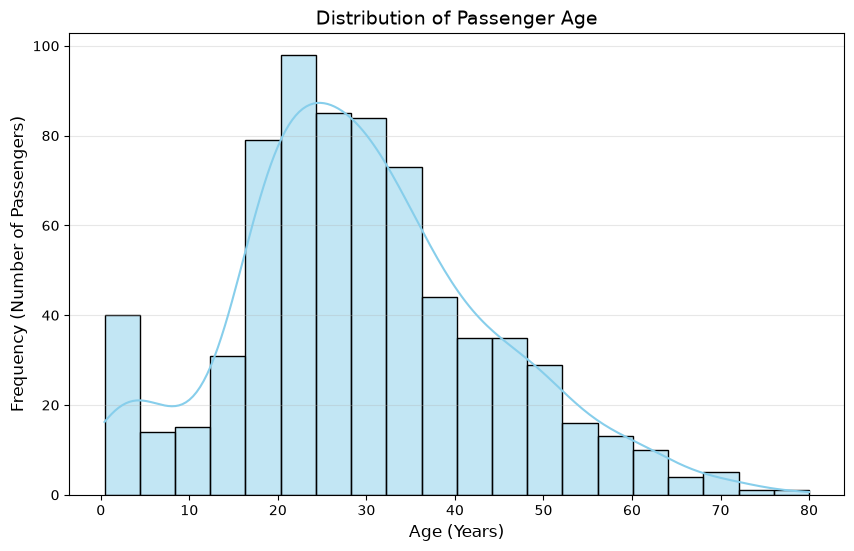

In [107]:
#Question 4 Histogram



plt.figure(figsize=(10, 6))

sns.histplot(data=df_clean, x='Age', bins=20, kde=True, color='skyblue', edgecolor='black')


plt.title('Distribution of Passenger Age', fontsize=14)
plt.xlabel('Age (Years)', fontsize=12)
plt.ylabel('Frequency (Number of Passengers)', fontsize=12)
plt.grid(axis='y', alpha=0.3)

plt.show()

This histogram of passenger age shows that the average passenger on the Titanic was approximately 30 years old. The distribution follows a roughly normal curve with a slight right skew toward older passengers, which likely reflects wealthier, older individuals who could afford higher-priced tickets, a pattern worth investigating further by comparing age distributions across passenger classes. Additionally, there is a noticeable spike of young children under five years old, which would also be interesting to explore in more detail.

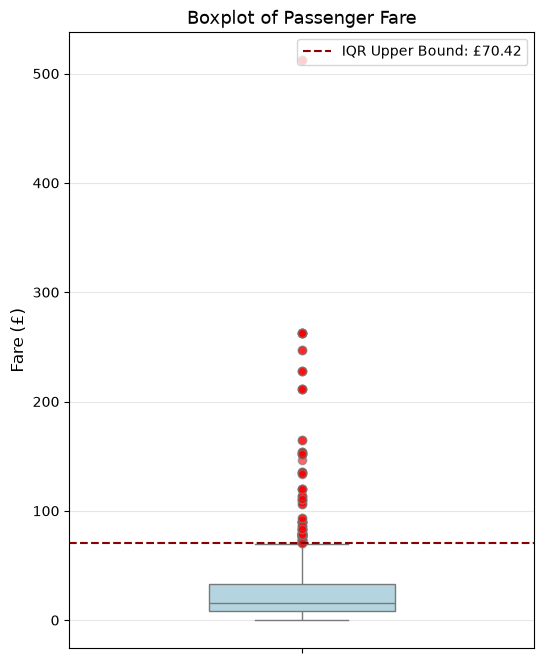

In [108]:
#Question 4 Boxplot


Q1 = df_clean['Fare'].quantile(0.25)
Q3 = df_clean['Fare'].quantile(0.75)
IQR = Q3 - Q1
upper_bound = Q3 + 1.5 * IQR

plt.figure(figsize=(6, 8))

sns.boxplot(
    data=df_clean, 
    y='Fare', 
    color='lightblue',
    width=0.4,
    flierprops=dict(marker='o', markerfacecolor='red', markersize=6, alpha=0.6)
)


plt.axhline(upper_bound, color='darkred', linestyle='--', linewidth=1.5, label=f'IQR Upper Bound: £{upper_bound:.2f}')


plt.title('Boxplot of Passenger Fare', fontsize=13)
plt.ylabel('Fare (£)', fontsize=12)
plt.legend(loc='upper right')
plt.grid(axis='y', alpha=0.3)

plt.show()


This boxplot clearly demonstrates the right-skewness of the data, as first-class fares are extraordinarily higher than those of the lower classes. There are no low-end outliers, which makes sense given minimum ticket pricing. However, it is interesting that certain fares are substantially higher than others within the same class, and it would be worth investigating whether any lower-class passengers paid unusually high ticket prices. It is possible that group and family tickets are listed as one fare. 

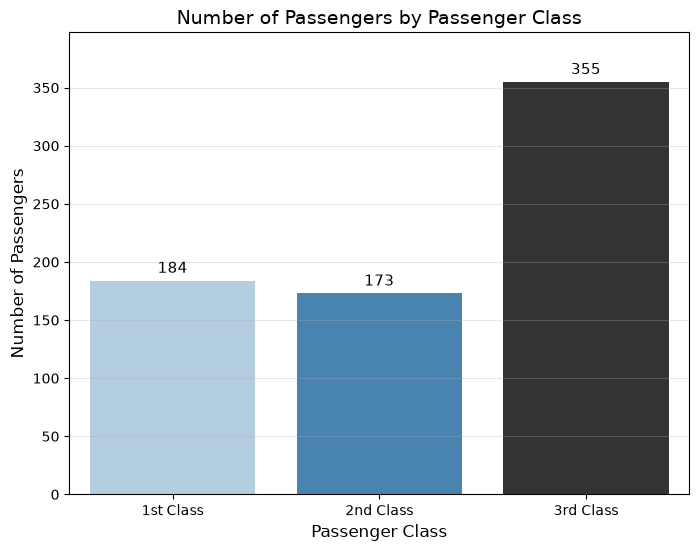

In [ ]:
#Question 4 Bar Chart

plt.figure(figsize=(8, 6))


ax = sns.countplot(
    data=df_clean, 
    x='Pclass', 
    order=[1, 2, 3], 
    hue='Pclass', 
    palette='Blues_d', 
    legend=False
)


for container in ax.containers:
    ax.bar_label(container, fontsize=11, padding=3)


plt.title('Number of Passengers by Passenger Class', fontsize=14)
plt.xlabel('Passenger Class', fontsize=12)
plt.ylabel('Number of Passengers', fontsize=12)
plt.xticks(ticks=[0, 1, 2], labels=['1st Class', '2nd Class', '3rd Class'])
plt.ylim(0, df_clean['Pclass'].value_counts().max() * 1.12)  # Add headroom for labels
plt.grid(axis='y', alpha=0.3)

plt.show()


This bar chart shows that the majority of passengers traveled in 3rd class, which aligns with a typical population distribution. Interestingly, 2nd class had slightly fewer passengers than 1st class, which deviates from a standard pyramid model where the middle tier would outnumber the upper tier. Because 2nd- and 3rd-class fares were relatively similar while 1st-class prices were substantially higher, it would be worth investigating the exact price differences and amenities offered across all three classes to understand why more travelers opted for 1st class over 2nd.

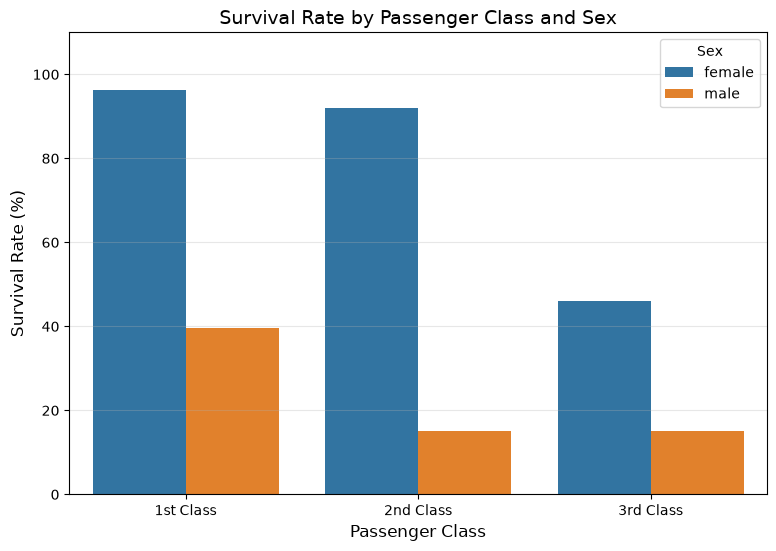

In [ ]:
#Question 4 Grouped Bar Chart

plot_df = df_clean.copy()
plot_df['Survival_Rate'] = plot_df['Survived'] * 100

plt.figure(figsize=(9, 6))


ax = sns.barplot(
    data=plot_df,
    x='Pclass',
    y='Survival_Rate',
    hue='Sex',
    order=[1, 2, 3],
    errorbar=None
)




plt.title('Survival Rate by Passenger Class and Sex', fontsize=14)
plt.xlabel('Passenger Class', fontsize=12)
plt.ylabel('Survival Rate (%)', fontsize=12)
plt.xticks(ticks=[0, 1, 2], labels=['1st Class', '2nd Class', '3rd Class'])
plt.ylim(0, 110)
plt.legend(title='Sex')
plt.grid(axis='y', alpha=0.3)

plt.show()


This grouped bar chart illustrates survival rates across sex and passenger class. As expected, women had a significantly higher overall survival rate due to the "women and children first" evacuation protocol. Upper-class passengers also survived at much higher rates, likely reflecting preferential treatment and easier access to lifeboats on the upper decks. Notably, female survival rates were nearly identical in 1st and 2nd class before dropping sharply in 3rd class, while male survival rates were similarly low across both 2nd and 3rd class—a pattern likely tied to lower-deck accommodations facing faster flooding and heavier congestion. Moving forward, it would be interesting to analyze male survival by age to see if the survivors were primarily young boys, and whether older men had higher survival odds in 1st class.ßß

Overall Findings:

The main findings of this data cleanup and analysis strongly align with historical accounts of the Titanic. The data confirms that women and children were prioritized during the evacuation, and that upper-class passengers had significantly higher survival rates than those in lower classes. Additionally, ticket prices were heavily right-skewed—reflecting the sharp contrast between luxury first-class suites and lower-cost tickets purchased by immigrants crossing the Atlantic while passenger ages followed a fairly standard distribution with a slight lean toward older travelers.

However, the dataset has a few notable limitations. Removing rows with missing values (excluding Cabin) slightly reduced the overall sample size, and because Cabin data was largely missing, it was not possible to test how exact room locations or deck levels impacted survival. Furthermore, because the Fare column records could have combined group ticket prices rather than individual per-person fares and because the dataset counts relatives without linking specific family members together, future analysis could use shared ticket numbers or surnames to calculate per-person ticket costs and examine survival rates across entire family units.